<a href="https://colab.research.google.com/github/San-Maansson/Stock_Analysis/blob/main/Black_Scholes_Merton_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:
import math
import numpy as np
import pandas as pd
import datetime as dt
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

Define the variables

In [38]:
# Define the variables
S = 45 # Underlying Price
K = 40 # Strike Price
T = 0.5 # Time to Expiration in Year
r = 0.1 # Risk-Free Rate
vol = 0.2 # Volatility

In [39]:
d1 = (math.log(S / K) + (r + 0.5 * vol ** 2) * T) / (vol * math.sqrt(T))
d2 = d1 - vol * math.sqrt(T)

Calculate Call Option Price

In [40]:
c = S * norm.cdf(d1) - K * math.exp(-r * T) * norm.cdf(d2)

Calculate Put Option Price

In [41]:
p = K * math.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

Print the results

In [42]:
print('The value of d1 is: ', round(d1,4))
print('The value of d2 is: ', round(d2,4))
print(f"Call Option Price: $ { round(c,2)}")
print(f"Put Option Price: $ { round(p,2)}")

The value of d1 is:  1.2571
The value of d2 is:  1.1157
Call Option Price: $ 7.29
Put Option Price: $ 0.34


Calculate Value At Risk (VAR)

Set time from to a certain number of years

In [43]:
years = 15

endDate = dt.datetime.now()
startDate = endDate - dt.timedelta(days=365*years)

Create a list of Tickers

In [52]:
tickers = ['SPY','AAPL', 'MSFT', 'GOOG', 'AMZN']

Download the daily adjusted close prices for the tickers

In [53]:
adj_close_df = pd.DataFrame()

for ticker in tickers:
    data = yf.download(ticker, start = startDate, end = endDate)
    adj_close_df[ticker] = data['Close']

#print(data)
print(adj_close_df)

/tmp/ipykernel_4818/2113146770.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start = startDate, end = endDate)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_4818/2113146770.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start = startDate, end = endDate)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_4818/2113146770.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start = startDate, end = endDate)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_4818/2113146770.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start = startDate, end = endDate)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykern

                   SPY        AAPL        MSFT        GOOG        AMZN
Date                                                                  
2011-04-15  101.172707    9.811688   19.424866   13.110321    9.000500
2011-04-18  100.038704    9.943223   19.202818   13.014964    8.917000
2011-04-19  100.613380   10.123302   19.256420   12.883787    8.941000
2011-04-20  101.984932   10.259630   19.723473   12.987542    9.193500
2011-04-21  102.505959   10.508025   19.539705   12.971981    9.294500
...                ...         ...         ...         ...         ...
2026-04-06  658.929993  258.859985  372.880005  297.660004  212.789993
2026-04-07  659.219971  253.500000  372.290009  303.929993  213.770004
2026-04-08  676.010010  258.899994  374.329987  314.739990  221.250000
2026-04-09  679.909973  260.489990  373.070007  316.369995  233.649994
2026-04-10  679.460022  260.480011  370.869995  315.720001  238.380005

[3768 rows x 5 columns]


Calculate the daily log returns and drop any NAs

In [54]:
log_returns = np.log(adj_close_df / adj_close_df.shift(1))
log_returns = log_returns.dropna()

print(log_returns)

                 SPY      AAPL      MSFT      GOOG      AMZN
Date                                                        
2011-04-18 -0.011272  0.013317 -0.011497 -0.007300 -0.009321
2011-04-19  0.005728  0.017949  0.002787 -0.010130  0.002688
2011-04-20  0.013540  0.013377  0.023965  0.008021  0.027849
2011-04-21  0.005096  0.023922 -0.009361 -0.001199  0.010926
2011-04-25 -0.001047  0.006565  0.003521 -0.000095 -0.002532
...              ...       ...       ...       ...       ...
2026-04-06  0.004716  0.011422 -0.001554  0.010809  0.014294
2026-04-07  0.000440 -0.020923 -0.001584  0.020845  0.004595
2026-04-08  0.025151  0.021078  0.005465  0.034949  0.034393
2026-04-09  0.005753  0.006123 -0.003372  0.005166  0.054531
2026-04-10 -0.000662 -0.000038 -0.005915 -0.002057  0.020042

[3767 rows x 5 columns]


Create an qqually weighted portfolio

In [55]:
portfolio_value = 1000000
weights = np.array([1/len(tickers)]*len(tickers))
print(weights)

[0.2 0.2 0.2 0.2 0.2]


Calculate the historical portfolio returns

In [57]:
historical_returns = (log_returns * weights).sum(axis =1)
print(historical_returns)

Date
2011-04-18   -0.005215
2011-04-19    0.003804
2011-04-20    0.017350
2011-04-21    0.005877
2011-04-25    0.001282
                ...   
2026-04-06    0.007937
2026-04-07    0.000675
2026-04-08    0.024207
2026-04-09    0.013640
2026-04-10    0.002274
Length: 3767, dtype: float64


Find the X-day historical returns

In [64]:
days = 5

historical_x_day_returns = historical_returns.rolling(window = days).sum()

Create a covaiance matrix for all the securities

In [65]:
cov_matrix = log_returns.cov() * 252

Calculate portfolio standard deviation

In [66]:
portfolio_std_dev = np.sqrt(weights.T @ cov_matrix @ weights)

Set different confidence levels to visualize

In [67]:
confidence_levels = [0.9, 0.95, 0.99]

Calculate VaR at different confidence levels

In [68]:
VaRs = []

for cl in confidence_levels:
  VaR = portfolio_value * portfolio_std_dev * norm.ppf(cl) *np.sqrt(days/252 )
  VaRs.append(VaR)

Print out the VaR results

In [69]:
print(f'{"Confindence Level":<20} {"Value at Risk":<20}')
print('-' * 40)

# Print each confidence level and its corresponding VaR value
for cl, VaR in zip(confidence_levels, VaRs):
    print(f'{cl * 100:>6.0f}%: {"":<8} ${VaR:>10,.2f}')

Confindence Level    Value at Risk       
----------------------------------------
    90%:          $ 39,275.56
    95%:          $ 50,409.63
    99%:          $ 71,295.30


Set labels, title, and legend

In [72]:
# Convert returns to dollar values for the histogram
historical_x_day_returns_dollars = historical_x_day_returns * portfolio_value

Plot the histogram

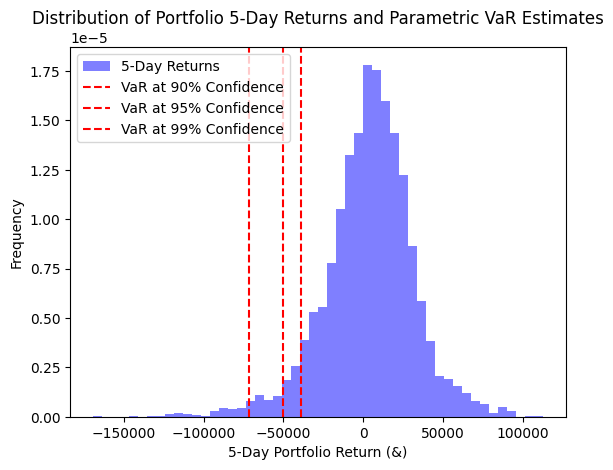

In [74]:
plt.hist(historical_x_day_returns_dollars, bins=50, density=True, alpha=0.5, label=f'{days}-Day Returns', color='b')

#Add vertical lines representing VaR at each confidence level
for cl, VaR in zip(confidence_levels, VaRs):
  plt.axvline(x=-VaR, color='r', linestyle='--', label='VaR at {}% Confidence'.format(int(cl*100)))

plt.xlabel(f'{days}-Day Portfolio Return (&)')
plt.ylabel('Frequency')
plt.title(f'Distribution of Portfolio {days}-Day Returns and Parametric VaR Estimates')
plt.legend()
plt.show()